# 02_03 Exponential, Gamma and Erlang

**Learning objectives**
- Model **waiting times** between random events with the Exponential, and the wait for the k-th event with the Erlang / Gamma.
- Prove and understand **memorylessness**, and connect the Exponential to the Poisson process from lesson 01_03.
- Derive the mean, variance and MGF, and see why a sum of exponentials is a Gamma.
- Solve three real problems (customer arrivals, battery lifetime, rainfall) by hand, in code and by simulation.

**Prerequisites:** [01_03 Poisson](../../module_01_discrete/notebooks/01_03_poisson.ipynb) (counts of events at a constant rate), [02_01 Uniform and Normal](02_01_uniform_normal.ipynb) (density, CDF).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Poisson($\lambda t$):** the number of events in a window of length $t$ when events arrive independently at a constant rate $\lambda$ per unit time. $P(N=k)=e^{-\lambda t}(\lambda t)^k/k!$.
- **PDF and CDF:** $F(x)=\int_0^xf(t)\,dt$; the **survival function** is $S(x)=P(X>x)=1-F(x)$.
- **Integration by parts:** $\int u\,dv=uv-\int v\,du$.
- **Factorial and Gamma function:** $n!=1\cdot2\cdots n$. The Gamma function extends it to non-integers: $\Gamma(k)=\int_0^\infty t^{k-1}e^{-t}dt$, with $\Gamma(n)=(n-1)!$ and $\Gamma(\tfrac12)=\sqrt\pi$.
- **MGF of a sum of independent variables** is the product of the MGFs.

## 3. Intuition and story

### 3.1 The waiting time between events
In lesson 01_03 we counted events (calls, requests, goals) in a fixed window and got a Poisson. Now flip the question: **how long do we wait between events?** If events arrive independently at rate $\lambda$ per hour, the time from now until the next event is **Exponential($\lambda$)**.

Why that shape? The chance of seeing *no* event during a time $t$ is the Poisson probability of 0 events with mean $\lambda t$: $e^{-\lambda t}$. So $P(\text{wait}>t)=e^{-\lambda t}$, exactly the Exponential survival function.

The Exponential is **memoryless**: if you have already waited 10 minutes for the bus (and it follows this model) the remaining wait has the same distribution as when you started. The process has no memory of the past: it is the continuous cousin of the Geometric distribution from 01_02.

### 3.2 Waiting for the k-th event
The time until the **k-th event** is the sum of k independent Exponential waits. That sum is **Erlang($k,\lambda$)**. When k is allowed to be any positive real number, it is the **Gamma** distribution, a flexible family for positive, right-skewed quantities (rainfall amounts, insurance claims, durations).

Let us see the connection directly: a simulated Poisson process, its gaps, and the counts.

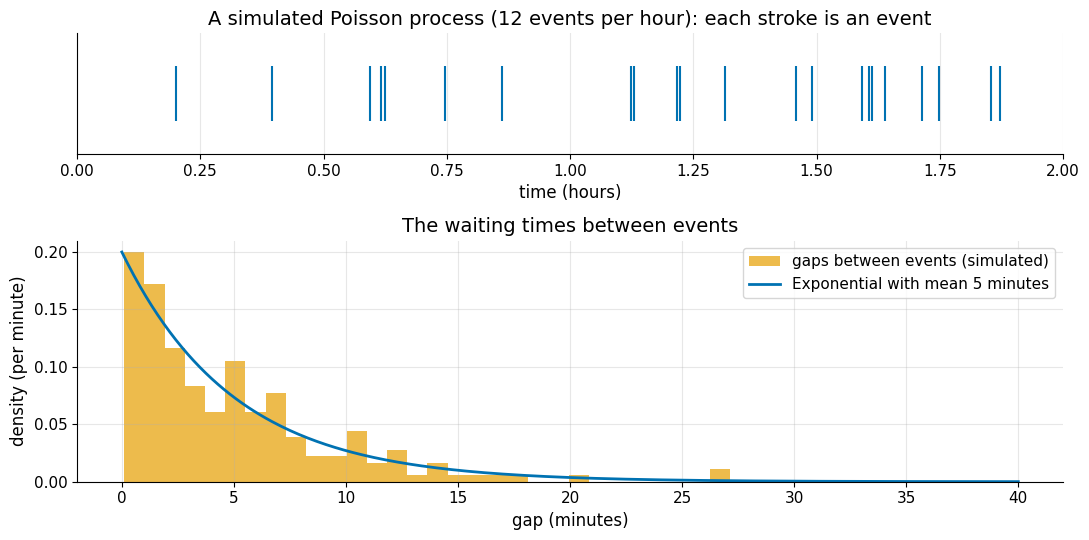

In [2]:
lam = 12                                              # 12 events per hour on average
gaps = rng.exponential(scale=1 / lam, size=200)       # waiting times in hours, mean 1/12 hour = 5 minutes
event_times = np.cumsum(gaps)
window = event_times <= 2.0                           # first 2 hours

fig, (ax_line, ax_gaps) = plt.subplots(2, 1, figsize=(11, 5.5), gridspec_kw={"height_ratios": [1, 2]})
ax_line.eventplot(event_times[window], colors=MAIN, lineoffsets=0, linelengths=0.8)
ax_line.set_xlim(0, 2)
ax_line.set_yticks([])
ax_line.set_title("A simulated Poisson process (12 events per hour): each stroke is an event")
ax_line.set_xlabel("time (hours)")

ax_gaps.hist(gaps * 60, bins=30, density=True, color=SIM, alpha=0.7, label="gaps between events (simulated)")
grid = np.linspace(0, 40, 300)
ax_gaps.plot(grid, stats.expon(scale=5).pdf(grid), color=MAIN, linewidth=2, label="Exponential with mean 5 minutes")
ax_gaps.set_title("The waiting times between events")
ax_gaps.set_xlabel("gap (minutes)")
ax_gaps.set_ylabel("density (per minute)")
ax_gaps.legend()
plt.tight_layout()
plt.show()

**In plain words.** Short gaps are the most common, long gaps are rare but possible, and the shape never "remembers" how long you have waited. The Exponential histogram is highest at 0: right after an event, another one soon is more likely than a long silence.

## 4. Formal definition

**Exponential($\lambda$):** support $x\ge0$, rate $\lambda>0$ (events per unit time). Equivalent: scale $\theta=1/\lambda$ (the mean wait).
$$f(x)=\lambda e^{-\lambda x},\qquad F(x)=1-e^{-\lambda x},\qquad S(x)=e^{-\lambda x}.$$

**Gamma($k,\theta$):** support $x>0$, shape $k>0$, scale $\theta>0$.
$$f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\,\theta^k}.$$
The CDF is the regularized incomplete gamma function. **Erlang($k,\lambda$)** is the Gamma with integer shape $k$ and $\theta=1/\lambda$. Exponential is Gamma with $k=1$.

**`scipy` parametrization:** `stats.expon(scale=1/lam)` and `stats.gamma(a=k, scale=theta)`. Note that `scipy` uses the **scale** (mean), not the rate.

## 5. Derivations

### 5.1 Exponential normalization and CDF
$\int_0^\infty\lambda e^{-\lambda x}dx=\big[-e^{-\lambda x}\big]_0^\infty=1$, and $F(x)=\int_0^x\lambda e^{-\lambda t}dt=1-e^{-\lambda x}$.

### 5.2 Exponential mean and variance
By parts with $u=x$, $dv=\lambda e^{-\lambda x}dx$:
$$E[X]=\int_0^\infty x\lambda e^{-\lambda x}dx=\big[-xe^{-\lambda x}\big]_0^\infty+\int_0^\infty e^{-\lambda x}dx=0+\frac1\lambda=\frac1\lambda.$$
Similarly $E[X^2]=\int_0^\infty x^2\lambda e^{-\lambda x}dx=\frac2{\lambda^2}$, so $\mathrm{Var}(X)=\frac2{\lambda^2}-\frac1{\lambda^2}=\frac1{\lambda^2}$. **Mean and SD are both $1/\lambda$**, a fingerprint of the Exponential.

**In plain words.** If events come 12 times per hour, the average wait is 1/12 hour = 5 minutes, and the typical deviation from that is also about 5 minutes: very variable.

### 5.3 MGF
$M(t)=\int_0^\infty e^{tx}\lambda e^{-\lambda x}dx=\dfrac{\lambda}{\lambda-t}$ for $t<\lambda$.

### 5.4 Memorylessness
For $s,t\ge0$, using $S(x)=e^{-\lambda x}$:
$$P(X>s+t\mid X>s)=\frac{S(s+t)}{S(s)}=\frac{e^{-\lambda(s+t)}}{e^{-\lambda s}}=e^{-\lambda t}=P(X>t).$$
The Exponential is the **only** continuous distribution with this property.

### 5.5 The link with the Poisson process
Let $N(t)\sim\text{Poisson}(\lambda t)$ count events up to time $t$. The first event time $T_1$ satisfies $\{T_1>t\}=\{N(t)=0\}$, so $P(T_1>t)=e^{-\lambda t}$: $T_1\sim\text{Exp}(\lambda)$. Events in a Poisson process have independent Exponential gaps.

### 5.6 Minimum of exponentials
If $X_1,\dots,X_n$ are independent Exp($\lambda_i$), then $P(\min>t)=\prod e^{-\lambda_it}=e^{-(\sum\lambda_i)t}$, so $\min\sim\text{Exp}(\sum\lambda_i)$. (Two independent queues with rates 5 and 7 produce the first event after $\text{Exp}(12)$.)

### 5.7 Erlang as a sum of exponentials
$T_k=X_1+\dots+X_k$ with iid Exp($\lambda$): the MGF is $\big(\frac\lambda{\lambda-t}\big)^k$. This is the MGF of the Gamma($k,\theta=1/\lambda$), so
$$E[T_k]=\frac k\lambda,\qquad\mathrm{Var}(T_k)=\frac k{\lambda^2}.$$

### 5.8 Erlang CDF through the Poisson
$\{T_k\le x\}$ means "the k-th event happened by time $x$", i.e. "at least $k$ events in $[0,x]$":
$$F_{T_k}(x)=P(N(x)\ge k)=1-\sum_{j=0}^{k-1}\frac{e^{-\lambda x}(\lambda x)^j}{j!}.$$
Differentiating this telescoping sum gives the Erlang density $\frac{\lambda^kx^{k-1}e^{-\lambda x}}{(k-1)!}$.

### 5.9 Gamma moments, mode, skewness
For general Gamma($k,\theta$): mean $k\theta$, variance $k\theta^2$, mode $(k-1)\theta$ for $k\ge1$ (0 if $k<1$), skewness $2/\sqrt k$, excess kurtosis $6/k$. The skewness shrinks as $k$ grows: the Gamma approaches a Normal (a sum of many exponentials, by the CLT).

## 6. Properties and relationships

- **Memoryless:** Exponential is the continuous analogue of the Geometric.
- **Poisson process:** counts in a window are Poisson($\lambda t$), gaps are Exponential($\lambda$), k-th arrival time is Erlang($k,\lambda$).
- **Additivity:** independent Gamma($k_1,\theta$) + Gamma($k_2,\theta$) = Gamma($k_1+k_2,\theta$) (same scale).
- **Scaling:** if $X\sim\text{Gamma}(k,\theta)$ then $cX\sim\text{Gamma}(k,c\theta)$.
- **Chi-square:** $\chi^2_\nu$ is Gamma($k=\nu/2$, $\theta=2$) (lesson 02_08).
- **Gamma-Poisson mixture:** a Poisson whose rate is Gamma-distributed gives a Negative Binomial (01_02).
- **Normal limit:** Gamma($k,\theta$) looks Normal for large $k$.
- **Hazard rate:** the Exponential has a constant hazard $\lambda$ ("failure rate"); the Weibull (02_05) generalizes this to rates that rise or fall.

## 7. 2D visuals

### 7.1 Exponential PDF and CDF
The PDF starts at lambda and decays; the CDF rises toward 1. The mean 1/lambda is where the CDF equals 1 - 1/e = 0.632.

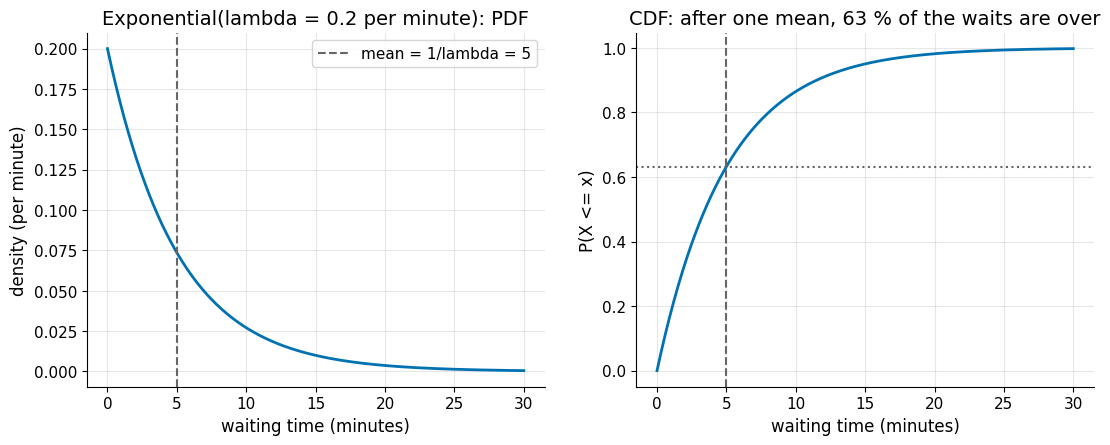

In [3]:
lam = 0.2                                         # rate: 0.2 events per minute, mean wait 5 minutes
dist = stats.expon(scale=1 / lam)
x_axis = np.linspace(0, 30, 400)

fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_pdf.plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2)
ax_pdf.axvline(1 / lam, color=NEUTRAL, linestyle="--", label="mean = 1/lambda = 5")
ax_pdf.set_title("Exponential(lambda = 0.2 per minute): PDF")
ax_pdf.set_xlabel("waiting time (minutes)")
ax_pdf.set_ylabel("density (per minute)")
ax_pdf.legend()

ax_cdf.plot(x_axis, dist.cdf(x_axis), color=MAIN, linewidth=2)
ax_cdf.axhline(1 - np.exp(-1), color=NEUTRAL, linestyle=":")
ax_cdf.axvline(1 / lam, color=NEUTRAL, linestyle="--")
ax_cdf.set_title("CDF: after one mean, 63 % of the waits are over")
ax_cdf.set_xlabel("waiting time (minutes)")
ax_cdf.set_ylabel("P(X <= x)")
plt.show()

### 7.2 Effect of the rate
A higher rate means events arrive faster, so waits are shorter: the curve starts higher and decays faster.

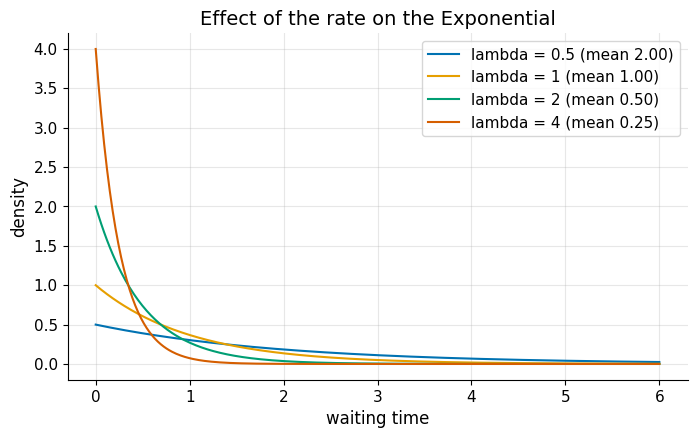

In [4]:
x_axis = np.linspace(0, 6, 400)
fig, ax = plt.subplots()
for rate, color in zip([0.5, 1, 2, 4], COLORS):
    ax.plot(x_axis, stats.expon(scale=1 / rate).pdf(x_axis), color=color, label=f"lambda = {rate} (mean {1 / rate:.2f})")
ax.set_title("Effect of the rate on the Exponential")
ax.set_xlabel("waiting time")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 7.3 Memorylessness, visually
After surviving s = 5 minutes, the conditional survival curve P(X > 5 + t | X > 5), plotted against t, lies exactly on top of the original survival curve P(X > t).

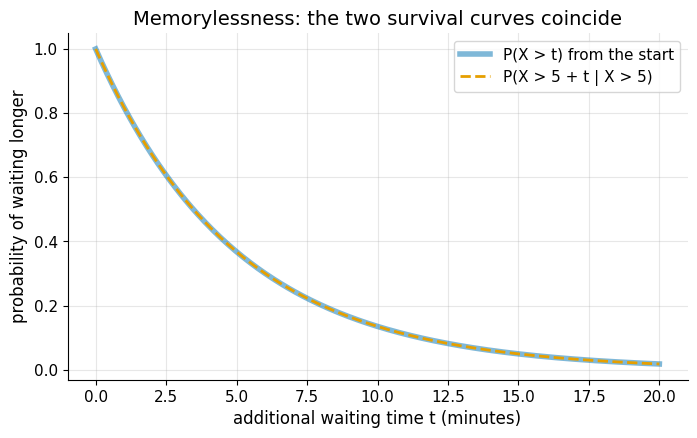

In [5]:
t_axis = np.linspace(0, 20, 300)
survival = dist.sf(t_axis)
survival_given_5 = dist.sf(5 + t_axis) / dist.sf(5)          # P(X > 5 + t | X > 5)

fig, ax = plt.subplots()
ax.plot(t_axis, survival, color=MAIN, linewidth=4, alpha=0.5, label="P(X > t) from the start")
ax.plot(t_axis, survival_given_5, color=SIM, linestyle="--", linewidth=2, label="P(X > 5 + t | X > 5)")
ax.set_title("Memorylessness: the two survival curves coincide")
ax.set_xlabel("additional waiting time t (minutes)")
ax.set_ylabel("probability of waiting longer")
ax.legend()
plt.show()
assert np.allclose(survival, survival_given_5)

### 7.4 Gamma: effect of the shape k
With the mean fixed at 10 (theta = 10 / k), the shape controls skewness. k < 1: a spike at 0 and a long tail; k = 1: Exponential; larger k: the bell appears.

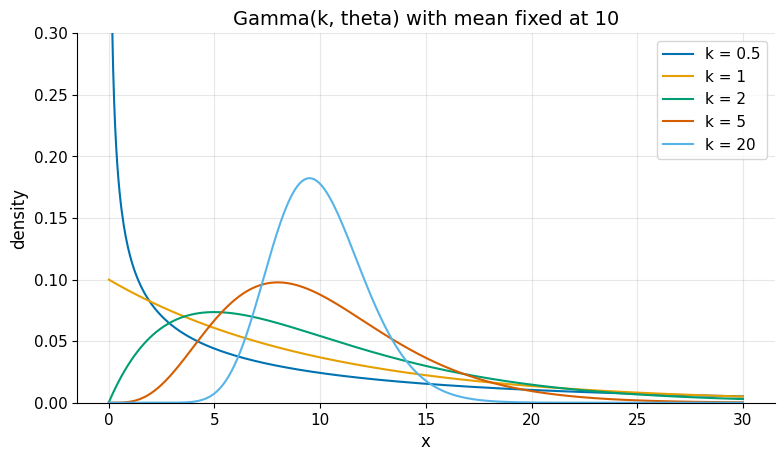

In [6]:
x_axis = np.linspace(0.01, 30, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
for shape, color in zip([0.5, 1, 2, 5, 20], COLORS + ["black"]):
    ax.plot(x_axis, stats.gamma(a=shape, scale=10 / shape).pdf(x_axis), color=color, label=f"k = {shape}")
ax.set_title("Gamma(k, theta) with mean fixed at 10")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_ylim(0, 0.3)
ax.legend()
plt.show()

### 7.5 Gamma: effect of the scale theta
With k = 2 fixed, the scale stretches the curve horizontally (and lowers the peak).

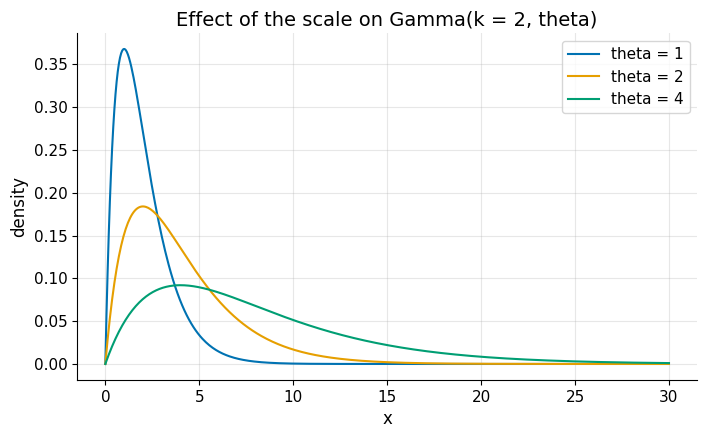

In [7]:
x_axis = np.linspace(0, 30, 500)
fig, ax = plt.subplots()
for scale, color in zip([1, 2, 4], COLORS):
    ax.plot(x_axis, stats.gamma(a=2, scale=scale).pdf(x_axis), color=color, label=f"theta = {scale}")
ax.set_title("Effect of the scale on Gamma(k = 2, theta)")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 7.6 Waiting for the k-th event: the Erlang becomes bell-shaped
For customers arriving at rate 0.2 per minute, the wait for the k-th customer is Erlang(k, 0.2). As k grows the distribution centers at k/lambda and looks more Normal.

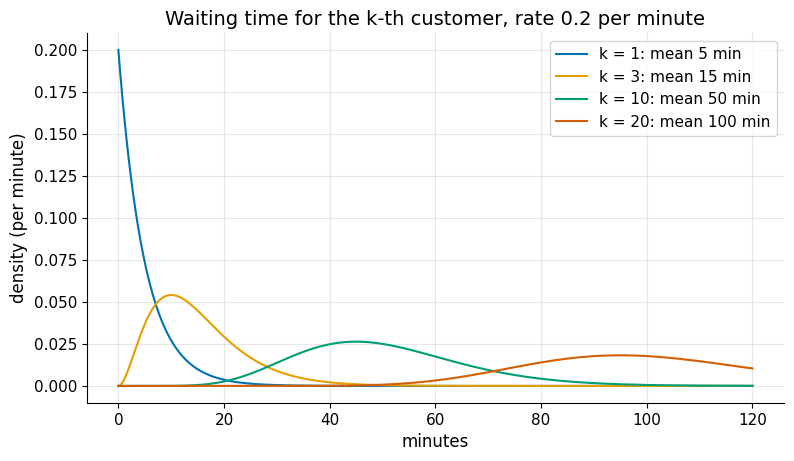

In [8]:
x_axis = np.linspace(0, 120, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
for k, color in zip([1, 3, 10, 20], COLORS):
    erlang = stats.gamma(a=k, scale=1 / 0.2)
    ax.plot(x_axis, erlang.pdf(x_axis), color=color, label=f"k = {k}: mean {erlang.mean():.0f} min")
ax.set_title("Waiting time for the k-th customer, rate 0.2 per minute")
ax.set_xlabel("minutes")
ax.set_ylabel("density (per minute)")
ax.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: Exponential PDF over (x, lambda)
The PDF is lambda times exp(-lambda x): higher rate means a taller start and a faster decay.

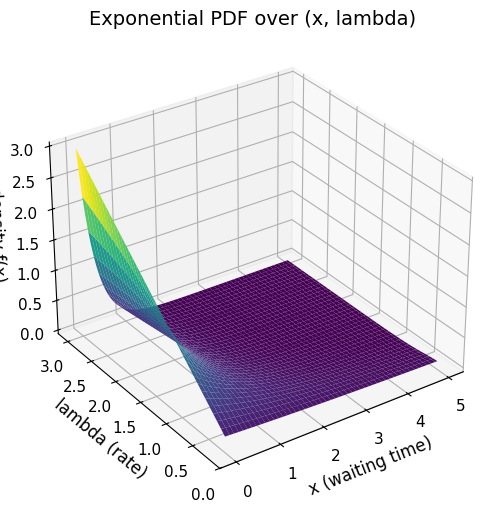

In [9]:
x_values = np.linspace(0, 5, 100)
rate_values = np.linspace(0.2, 3, 40)
X, R = np.meshgrid(x_values, rate_values)
Z = R * np.exp(-R * X)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, R, Z, cmap="viridis", edgecolor="none")
ax.set_title("Exponential PDF over (x, lambda)")
ax.set_xlabel("x (waiting time)")
ax.set_ylabel("lambda (rate)")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.2 Static: Gamma PDF over (x, k)
With scale theta = 1, the ridge moves right as k grows (mode at k - 1) and the shape moves from a spike at 0 to a bell.

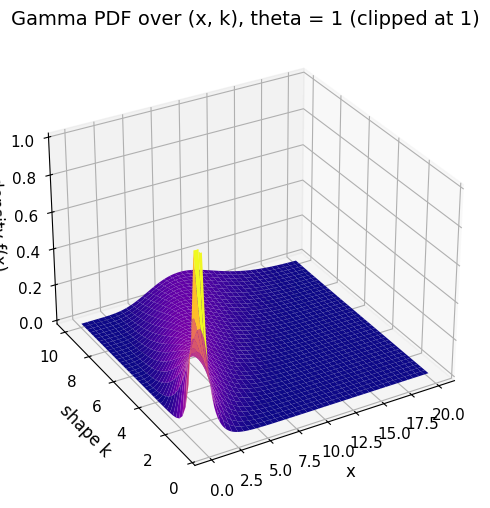

In [10]:
x_values = np.linspace(0.05, 20, 160)
shape_values = np.linspace(0.5, 10, 40)
X2, K2 = np.meshgrid(x_values, shape_values)
Z2 = stats.gamma.pdf(X2, a=K2, scale=1)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X2, K2, np.minimum(Z2, 1.0), cmap="plasma", edgecolor="none")
ax.set_title("Gamma PDF over (x, k), theta = 1 (clipped at 1)")
ax.set_xlabel("x")
ax.set_ylabel("shape k")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Interactive Plotly version
The Gamma surface of 8.2; drag to rotate.

In [11]:
fig = go.Figure(go.Surface(x=x_values, y=shape_values, z=np.minimum(Z2, 1.0), colorscale="Plasma"))
fig.update_layout(title="Gamma PDF over (x, k), theta = 1 (clipped at 1)", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="shape k", zaxis_title="density f(x)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PDF
50,000 exponential waits (rate 0.2 per minute) against the PDF.

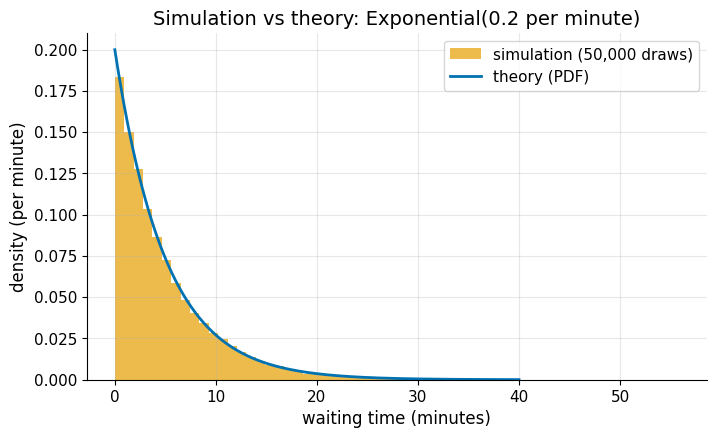

sample mean 5.005 (theory 5), sample SD 5.008 (theory 5)


In [12]:
samples = rng.exponential(scale=5, size=50_000)            # numpy takes the scale = mean
x_axis = np.linspace(0, 40, 400)

fig, ax = plt.subplots()
ax.hist(samples, bins=60, density=True, color=SIM, alpha=0.7, label="simulation (50,000 draws)")
ax.plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2, label="theory (PDF)")
ax.set_title("Simulation vs theory: Exponential(0.2 per minute)")
ax.set_xlabel("waiting time (minutes)")
ax.set_ylabel("density (per minute)")
ax.legend()
plt.show()
print(f"sample mean {samples.mean():.3f} (theory 5), sample SD {samples.std():.3f} (theory 5)")

### 9.2 Running mean converges to 1/lambda

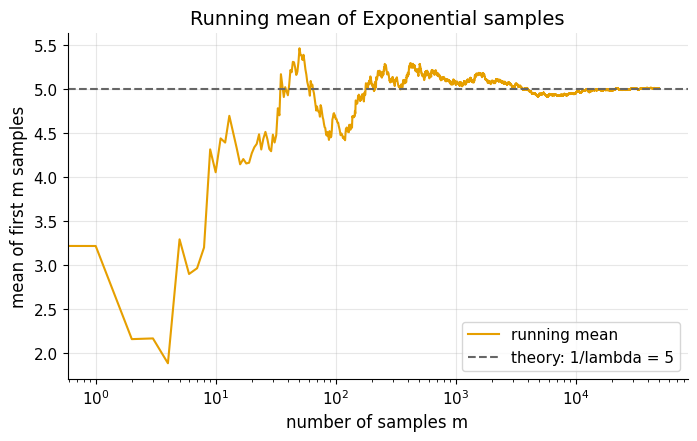

In [13]:
running_mean = np.cumsum(samples) / np.arange(1, len(samples) + 1)
fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(5, color=NEUTRAL, linestyle="--", label="theory: 1/lambda = 5")
ax.set_xscale("log")
ax.set_title("Running mean of Exponential samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.legend()
plt.show()

### 9.3 A sum of exponentials is a Gamma
We add k = 5 independent exponential waits (each with mean 5 minutes). The histogram of the sums matches Gamma(5, scale 5).

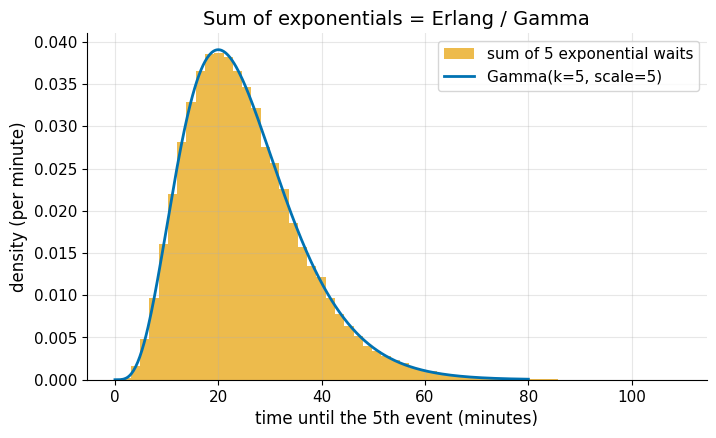

mean 24.95 (theory 25), variance 124.4 (theory 125)


In [14]:
k = 5
five_waits = rng.exponential(scale=5, size=(50_000, k)).sum(axis=1)
x_axis = np.linspace(0, 80, 400)

fig, ax = plt.subplots()
ax.hist(five_waits, bins=60, density=True, color=SIM, alpha=0.7, label="sum of 5 exponential waits")
ax.plot(x_axis, stats.gamma(a=k, scale=5).pdf(x_axis), color=MAIN, linewidth=2, label="Gamma(k=5, scale=5)")
ax.set_title("Sum of exponentials = Erlang / Gamma")
ax.set_xlabel("time until the 5th event (minutes)")
ax.set_ylabel("density (per minute)")
ax.legend()
plt.show()
print(f"mean {five_waits.mean():.2f} (theory 25), variance {five_waits.var():.1f} (theory {k * 25})")

## 10. `scipy.stats` cheat sheet

Both use `scale` (the mean for the Exponential), not the rate.

In [15]:
e = stats.expon(scale=5)                 # rate 0.2 per minute
print("expon pdf(2)     :", round(e.pdf(2), 5))
print("expon cdf(2)     P(X <= 2):", round(e.cdf(2), 5))
print("expon sf(10)     P(X > 10):", round(e.sf(10), 5))
print("expon ppf(0.9)   :", round(e.ppf(0.9), 3))
print("expon mean, std  :", e.mean(), e.std())
print("expon rvs(3)     :", e.rvs(size=3, random_state=1).round(2))

g = stats.gamma(a=5, scale=5)            # Erlang(5, 0.2)
print("gamma mean, var  :", g.mean(), g.var())
print("gamma cdf(30)    P(T5 <= 30):", round(g.cdf(30), 5))
print("gamma ppf(0.9)   :", round(g.ppf(0.9), 3))
print("gamma stats mvsk :", np.round(g.stats(moments="mvsk"), 3))

expon pdf(2)     : 0.13406
expon cdf(2)     P(X <= 2): 0.32968
expon sf(10)     P(X > 10): 0.13534
expon ppf(0.9)   : 11.513
expon mean, std  : 5.0 5.0
expon rvs(3)     : [2.7  6.37 0.  ]
gamma mean, var  : 25.0 125.0
gamma cdf(30)    P(T5 <= 30): 0.71494
gamma ppf(0.9)   : 39.968
gamma stats mvsk : [ 25.    125.      0.894   1.2  ]


**Fitting:** for the Exponential the MLE of the scale is the sample mean. For the Gamma use `stats.gamma.fit(data, floc=0)` (fix the location at 0).

In [16]:
waits = rng.gamma(shape=2.5, scale=4.0, size=3000)
shape_hat, loc_hat, scale_hat = stats.gamma.fit(waits, floc=0)
print(f"true shape 2.5, scale 4.0 -> fitted shape {shape_hat:.2f}, scale {scale_hat:.2f}")
print(f"exponential MLE of the scale (= sample mean): {waits.mean():.2f}")

true shape 2.5, scale 4.0 -> fitted shape 2.49, scale 4.06
exponential MLE of the scale (= sample mean): 10.09


## 11. Real-world worked examples

Three examples. Example 1 is the main one (all five steps).

---
### Example 1 (main): customer arrivals at a store

**Scenario (illustrative numbers).** Customers enter a store at an average of **12 per hour**, independently (a Poisson process). That is a rate of $\lambda=12/60=0.2$ per minute, so the mean gap is 5 minutes.

**Questions**
1. What is the probability that the gap between two customers is **less than 2 minutes**?
2. What is the probability that the gap is **more than 10 minutes** (a quiet spell)?
3. The owner wants to close the till for a break only after **5 customers** have arrived. What are the mean, SD and **90th percentile** of the time until the 5th customer? What is the probability that the 5th customer arrives **within 30 minutes**?

### 11.1 By hand
**Q1.** $P(X<2)=1-e^{-\lambda\cdot2}=1-e^{-0.4}=1-0.6703=0.3297$.

**Q2.** $P(X>10)=e^{-0.2\times10}=e^{-2}=0.1353$.

**Q3.** The time to the 5th customer is Erlang($k=5,\lambda=0.2$): mean $k/\lambda=5/0.2=25$ minutes, SD $\sqrt k/\lambda=\sqrt5/0.2=11.18$ minutes. For the probability, use the Poisson link of section 5.8: the 5th customer arrives within 30 minutes if **at least 5 customers** arrive in 30 minutes, where the count is Poisson($\lambda t=0.2\times30=6$):
$$P(T_5\le30)=1-\sum_{j=0}^{4}\frac{e^{-6}6^j}{j!}=1-e^{-6}\Big(1+6+18+36+54\Big)=1-0.002479\times115=0.7149.$$
The 90th percentile has no simple formula; we find it by the same Poisson sum and a search in code.

In [17]:
import math

rate_per_minute = 12 / 60

p_gap_under_2_hand = 1 - math.exp(-rate_per_minute * 2)
p_gap_over_10_hand = math.exp(-rate_per_minute * 10)
k_customers = 5
mean_hand = k_customers / rate_per_minute
sd_hand = math.sqrt(k_customers) / rate_per_minute

def erlang_cdf_by_poisson_sum(t, k, rate):
    # P(T_k <= t) = 1 - sum_{j<k} e^(-rate t) (rate t)^j / j!   (at least k events by time t)
    mean_count = rate * t
    total = 0.0
    for j in range(k):
        total += math.exp(-mean_count) * mean_count**j / math.factorial(j)
    return 1 - total

p_within_30_hand = erlang_cdf_by_poisson_sum(30, k_customers, rate_per_minute)

# 90th percentile by bisection on the CDF: halve the interval until it is tiny
low, high = 0.0, 200.0
for _ in range(60):
    middle = (low + high) / 2
    if erlang_cdf_by_poisson_sum(middle, k_customers, rate_per_minute) < 0.90:
        low = middle
    else:
        high = middle
p90_hand = (low + high) / 2
print(f"P(gap<2) = {p_gap_under_2_hand:.4f}, P(gap>10) = {p_gap_over_10_hand:.4f}")
print(f"5th customer: mean {mean_hand:.1f}, SD {sd_hand:.2f}, P(within 30 min) = {p_within_30_hand:.4f}, 90th percentile = {p90_hand:.2f} min")

P(gap<2) = 0.3297, P(gap>10) = 0.1353
5th customer: mean 25.0, SD 11.18, P(within 30 min) = 0.7149, 90th percentile = 39.97 min


### 11.2 In code with `scipy`, and the asserts

In [18]:
gap = stats.expon(scale=1 / rate_per_minute)
fifth = stats.gamma(a=k_customers, scale=1 / rate_per_minute)

p_gap_under_2_code = gap.cdf(2)
p_gap_over_10_code = gap.sf(10)
p_within_30_code = fifth.cdf(30)
p90_code = fifth.ppf(0.90)

assert np.isclose(p_gap_under_2_hand, p_gap_under_2_code)
assert np.isclose(p_gap_over_10_hand, p_gap_over_10_code)
assert np.isclose(mean_hand, fifth.mean()) and np.isclose(sd_hand, fifth.std())
assert np.isclose(p_within_30_hand, p_within_30_code)
assert np.isclose(p90_hand, p90_code)
assert np.isclose(p_within_30_code, stats.poisson(6).sf(4))          # the Poisson link
print(f"P(gap < 2 min) = {p_gap_under_2_code:.4f}, P(gap > 10 min) = {p_gap_over_10_code:.4f}")
print(f"5th customer: mean {fifth.mean():.1f}, SD {fifth.std():.2f}, 90th percentile {p90_code:.2f}, P(within 30) = {p_within_30_code:.4f}")

P(gap < 2 min) = 0.3297, P(gap > 10 min) = 0.1353
5th customer: mean 25.0, SD 11.18, 90th percentile 39.97, P(within 30) = 0.7149


### 11.3 Verify by simulation
Simulate 200,000 shifts of the arrival process: draw gaps, accumulate them, and read off the time of the 5th customer.

In [19]:
gap_samples = rng.exponential(scale=5, size=1_000_000)
arrival_times = rng.exponential(scale=5, size=(200_000, 5)).cumsum(axis=1)
fifth_arrival = arrival_times[:, 4]

print(f"P(gap<2):  exact {p_gap_under_2_code:.4f}  simulated {np.mean(gap_samples < 2):.4f}")
print(f"P(gap>10): exact {p_gap_over_10_code:.4f}  simulated {np.mean(gap_samples > 10):.4f}")
print(f"5th customer: mean exact {fifth.mean():.2f} sim {fifth_arrival.mean():.2f}; P(within 30) exact {p_within_30_code:.4f} sim {np.mean(fifth_arrival <= 30):.4f}; 90th pct exact {p90_code:.2f} sim {np.percentile(fifth_arrival, 90):.2f}")
assert abs(np.mean(fifth_arrival <= 30) - p_within_30_code) < 0.005
assert abs(np.percentile(fifth_arrival, 90) - p90_code) < 0.3

P(gap<2):  exact 0.3297  simulated 0.3299
P(gap>10): exact 0.1353  simulated 0.1354
5th customer: mean exact 25.00 sim 25.00; P(within 30) exact 0.7149 sim 0.7152; 90th pct exact 39.97 sim 39.87


### 11.4 Plots with the regions shaded

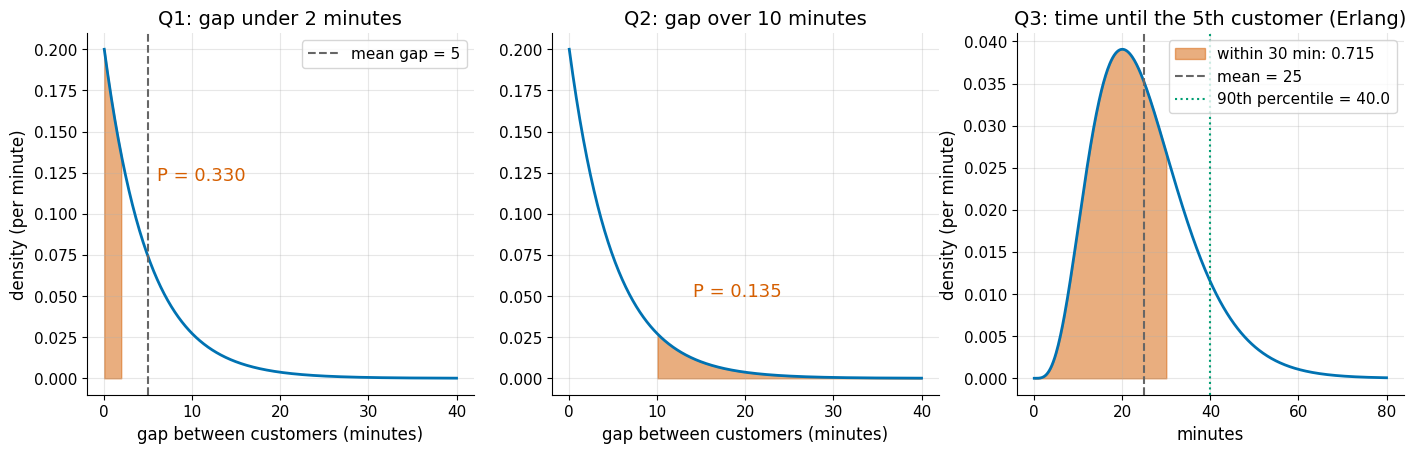

In [20]:
x_axis = np.linspace(0, 40, 500)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

short = x_axis < 2
axes[0].plot(x_axis, gap.pdf(x_axis), color=MAIN, linewidth=2)
axes[0].fill_between(x_axis[short], gap.pdf(x_axis[short]), color=HIGHLIGHT, alpha=0.5)
axes[0].axvline(5, color=NEUTRAL, linestyle="--", label="mean gap = 5")
axes[0].set_title("Q1: gap under 2 minutes")
axes[0].text(6, 0.12, f"P = {p_gap_under_2_code:.3f}", color=HIGHLIGHT, fontsize=13)
axes[0].set_xlabel("gap between customers (minutes)")
axes[0].set_ylabel("density (per minute)")
axes[0].legend()

long = x_axis > 10
axes[1].plot(x_axis, gap.pdf(x_axis), color=MAIN, linewidth=2)
axes[1].fill_between(x_axis[long], gap.pdf(x_axis[long]), color=HIGHLIGHT, alpha=0.5)
axes[1].set_title("Q2: gap over 10 minutes")
axes[1].text(14, 0.05, f"P = {p_gap_over_10_code:.3f}", color=HIGHLIGHT, fontsize=13)
axes[1].set_xlabel("gap between customers (minutes)")

t_axis = np.linspace(0, 80, 500)
axes[2].plot(t_axis, fifth.pdf(t_axis), color=MAIN, linewidth=2)
within = t_axis <= 30
axes[2].fill_between(t_axis[within], fifth.pdf(t_axis[within]), color=HIGHLIGHT, alpha=0.5, label=f"within 30 min: {p_within_30_code:.3f}")
axes[2].axvline(fifth.mean(), color=NEUTRAL, linestyle="--", label="mean = 25")
axes[2].axvline(p90_code, color=COLORS[2], linestyle=":", label=f"90th percentile = {p90_code:.1f}")
axes[2].set_title("Q3: time until the 5th customer (Erlang)")
axes[2].set_xlabel("minutes")
axes[2].set_ylabel("density (per minute)")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- About **1 gap in 3 is shorter than 2 minutes**: customers often arrive in clusters even though the average gap is 5 minutes. A staffing plan based on the average gap would miss this randomness.
- **Quiet spells of more than 10 minutes happen about 14 % of the time**, roughly 1 gap in 7. Do not assume that a 10-minute silence means that something is wrong.
- **Decision for the break:** the 5th customer takes 25 minutes on average but can take **40 minutes or more** (the 90th percentile, 39.97). The owner should not promise "5 customers every half hour": that happens only about 71 % of the time. A break rule such as "close the till after 5 customers or 40 minutes, whichever comes first" is more realistic.

---
### Example 2: battery lifetime and memorylessness

**Scenario (illustrative).** A sensor battery lasts, on average, **500 hours**; assume an Exponential lifetime (constant failure rate $\lambda=1/500$ per hour).

**Questions:** (a) probability the battery lasts more than 300 hours; (b) given that it has survived 300 hours, the probability it lasts at least another 300; (c) warranty: the period such that only 5 % of batteries fail within it.

**By hand.** (a) $e^{-300/500}=e^{-0.6}=0.5488$. (b) By memorylessness the answer is the same as (a): $0.5488$. (c) $F(w)=0.05\Rightarrow1-e^{-w/500}=0.05\Rightarrow w=-500\ln0.95=25.6$ hours.

In [21]:
battery = stats.expon(scale=500)
p_over_300_hand = math.exp(-300 / 500)
p_conditional_hand = math.exp(-300 / 500)                       # memorylessness
warranty_hand = -500 * math.log(0.95)

p_conditional_code = battery.sf(600) / battery.sf(300)           # P(X > 600 | X > 300)
assert np.isclose(p_over_300_hand, battery.sf(300))
assert np.isclose(p_conditional_hand, p_conditional_code)
assert np.isclose(warranty_hand, battery.ppf(0.05))
print(f"P(>300 h) = {battery.sf(300):.4f}; P(another 300 h | survived 300 h) = {p_conditional_code:.4f}; warranty = {battery.ppf(0.05):.1f} hours")

lifetimes = rng.exponential(500, size=300_000)
survivors = lifetimes[lifetimes > 300]
print(f"simulation: P(>300) = {np.mean(lifetimes > 300):.4f}; among survivors, share lasting 300 h more = {np.mean(survivors > 600):.4f}")

P(>300 h) = 0.5488; P(another 300 h | survived 300 h) = 0.5488; warranty = 25.6 hours
simulation: P(>300) = 0.5503; among survivors, share lasting 300 h more = 0.5485


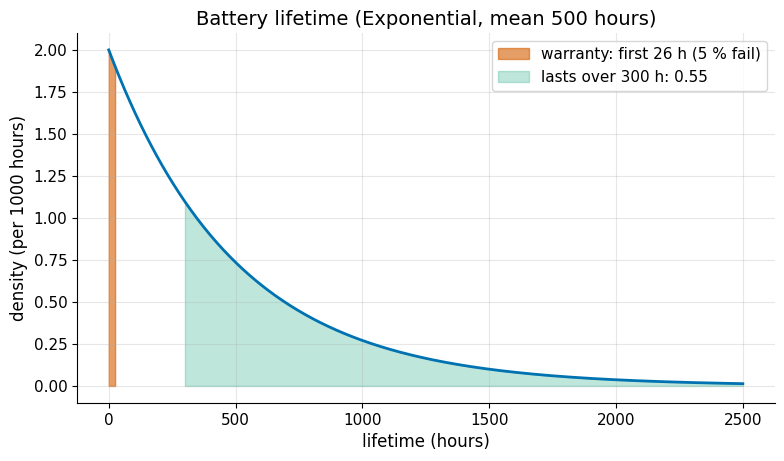

In [22]:
x_axis = np.linspace(0, 2500, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, battery.pdf(x_axis) * 1000, color=MAIN, linewidth=2)
fail_early = x_axis <= battery.ppf(0.05)
ax.fill_between(x_axis[fail_early], battery.pdf(x_axis[fail_early]) * 1000, color=HIGHLIGHT, alpha=0.6, label=f"warranty: first {battery.ppf(0.05):.0f} h (5 % fail)")
survive = x_axis >= 300
ax.fill_between(x_axis[survive], battery.pdf(x_axis[survive]) * 1000, color=COLORS[2], alpha=0.25, label=f"lasts over 300 h: {battery.sf(300):.2f}")
ax.set_title("Battery lifetime (Exponential, mean 500 hours)")
ax.set_xlabel("lifetime (hours)")
ax.set_ylabel("density (per 1000 hours)")
ax.legend()
plt.show()

**Interpretation.** A battery that has already run 300 hours is **not "due"** to fail and is no more worn out in this model: its chance of lasting another 300 hours is still 55 %. That is realistic for random shocks (a surge, a drop) but not for wear and tear; for aging parts, use the Weibull (02_05). A warranty of **25 hours** would cover only 5 % of the batteries: with exponential lifetimes, early failures are the most likely failures.

---
### Example 3: rainfall on a rainy day (a Gamma with k below 1)

**Scenario (illustrative).** On rainy days in a region, the daily rainfall (mm) follows a Gamma distribution with **shape $k=0.8$ and scale $	heta=8$ mm**. Since $k<1$, most rainy days are light, but there are occasional heavy downpours.

**Questions:** (a) mean rainfall on a rainy day; (b) probability of more than 20 mm (flood watch); (c) the amount exceeded on only 1 % of rainy days.

**By hand.** (a) mean $=k	heta=0.8	imes8=6.4$ mm; SD $=\sqrt k\,	heta=7.16$ mm. (b) and (c) need the incomplete gamma function (no elementary formula for $k=0.8$); we compute $P(X>20)$ by numerical integration of the density with a plain loop, and compare with `scipy`.

In [23]:
rain = stats.gamma(a=0.8, scale=8)

def gamma_pdf_by_formula(x, k, theta):
    # x^(k-1) e^(-x/theta) / (Gamma(k) theta^k)
    return x ** (k - 1) * math.exp(-x / theta) / (math.gamma(k) * theta**k)

# integrate the density from 20 to 400 mm with the trapezoid rule (small steps, plain loop)
step = 0.01
area = 0.0
x = 20.0
while x < 400:
    area += 0.5 * (gamma_pdf_by_formula(x, 0.8, 8) + gamma_pdf_by_formula(x + step, 0.8, 8)) * step
    x += step
p_over_20_hand = area
assert np.isclose(p_over_20_hand, rain.sf(20), atol=1e-4)
print(f"mean = {rain.mean():.2f} mm, SD = {rain.std():.2f} mm")
print(f"P(> 20 mm): numerical integral {p_over_20_hand:.4f}, scipy {rain.sf(20):.4f}")
print(f"amount exceeded on 1% of rainy days: {rain.ppf(0.99):.1f} mm")

simulated_rain = rng.gamma(shape=0.8, scale=8, size=500_000)
print(f"simulation: P(>20 mm) = {np.mean(simulated_rain > 20):.4f}; 99th percentile = {np.percentile(simulated_rain, 99):.1f} mm; share of days under 2 mm = {np.mean(simulated_rain < 2):.3f}")
assert abs(np.mean(simulated_rain > 20) - rain.sf(20)) < 0.003

mean = 6.40 mm, SD = 7.16 mm
P(> 20 mm): numerical integral 0.0553, scipy 0.0553
amount exceeded on 1% of rainy days: 33.0 mm
simulation: P(>20 mm) = 0.0552; 99th percentile = 33.1 mm; share of days under 2 mm = 0.318


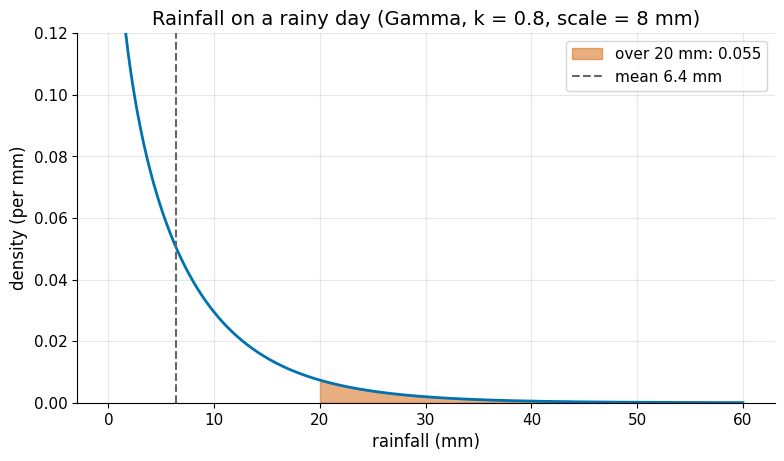

In [24]:
x_axis = np.linspace(0.05, 60, 800)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, rain.pdf(x_axis), color=MAIN, linewidth=2)
heavy = x_axis > 20
ax.fill_between(x_axis[heavy], rain.pdf(x_axis[heavy]), color=HIGHLIGHT, alpha=0.5, label=f"over 20 mm: {rain.sf(20):.3f}")
ax.axvline(rain.mean(), color=NEUTRAL, linestyle="--", label="mean 6.4 mm")
ax.set_ylim(0, 0.12)
ax.set_title("Rainfall on a rainy day (Gamma, k = 0.8, scale = 8 mm)")
ax.set_xlabel("rainfall (mm)")
ax.set_ylabel("density (per mm)")
ax.legend()
plt.show()

**Interpretation.** The average rainy day brings 6.4 mm, but the distribution is highly skewed: the density is infinite at 0 (k below 1), so very light rain is the most common, and about **5.5 % of rainy days exceed 20 mm**. A drainage design for the "99 % day" must handle about **33 mm**, more than five times the average. Designing for the mean (6.4 mm) would fail on every rainy day above that, which is a large share of them.

## 12. Where it is used

### Statistics
- **Survival and reliability analysis:** Exponential as the constant-hazard baseline; Gamma and Weibull as richer models.
- **Poisson-process modelling:** arrival times, inter-event times, tests for randomness of events.
- **Bayesian statistics:** the Gamma is the conjugate prior for a Poisson rate (Module 07); the Exponential's rate also has a Gamma prior.

### Data science
- **Queueing and capacity planning:** inter-arrival times of requests, customers or tickets (Module 11).
- **Time-to-event features:** time since last purchase, time between failures, churn timing.
- **Insurance and rainfall amounts:** Gamma for positive, skewed amounts.

### ML and AI
- **Poisson-process models** for event streams (temporal point processes, Hawkes processes).
- **Gamma and Exponential priors** in Bayesian models, and Gamma-distributed noise or scale parameters (e.g. the Student-t as a Gamma mixture of Normals).
- **Exponential decay** schedules and hazard models in reinforcement learning (random episode termination).

## 13. Common pitfalls and misconceptions

- **Rate vs scale:** the textbook Exponential uses the rate lambda; `scipy` and `numpy` use the **scale = 1/lambda** (the mean). Passing the rate as `scale` is the most common bug.
- **Memorylessness is a strong assumption:** it fits random shocks, not wear-out or "due" events (buses with a timetable are not Exponential).
- **Units must match:** a rate of 12 per hour is 0.2 per minute. Convert before using.
- **Mean = SD for the Exponential:** if real waiting times have a much smaller SD than the mean (regular arrivals), they are not Exponential.
- **Gamma parametrization:** (shape, scale) in `scipy`; many books use (shape, rate). Check before using formulas.
- **Erlang CDF via Poisson:** the roles flip: "k-th arrival by time t" equals "at least k arrivals in [0, t]".
- **Gamma with k below 1** has an infinite density at 0 (not an error).

## 14. Exercises

1. Calls arrive at 3 per hour. What is the probability that the next call comes within 10 minutes? After more than 30 minutes?
2. A light bulb has Exponential lifetime with mean 1,000 hours. It has already burned for 800 hours. What is the probability it lasts at least 500 more?
3. Two independent queues have arrival rates 5 and 7 per hour. What is the distribution of the time to the next arrival in either queue, and what is its mean?
4. Show that for Exp($\lambda$) the median is $\ln2/\lambda$ and is smaller than the mean $1/\lambda$.
5. Using code, find the probability that the 3rd arrival (rate 2 per minute) happens within 2 minutes, both with Gamma and with the Poisson sum.
6. Gamma(k = 4, theta = 2): mean, variance, mode and the probability of exceeding 12.
7. (Harder) Show that if $X\sim\text{Exp}(\lambda)$ then $\lceil X\rceil$ is Geometric with $p=1-e^{-\lambda}$.
8. (Harder) Simulate the sum of 30 Exponential(1) values 20,000 times, compare with Gamma(30, 1), and compute how close the Normal approximation $N(30,30)$ is at the 95th percentile.

Solutions are at the end.

## 15. Summary table

| Item | Exponential | Gamma / Erlang |
|---|---|---|
| Parameters | rate lambda > 0 (scale 1/lambda) | shape k > 0, scale theta > 0 (Erlang: integer k) |
| Support | x >= 0 | x > 0 |
| PDF | lambda exp(-lambda x) | x^(k-1) exp(-x/theta) / (Gamma(k) theta^k) |
| Mean | 1/lambda | k theta |
| Variance | 1/lambda^2 | k theta^2 |
| Skewness | 2 | 2 / sqrt(k) |
| Special property | memoryless; constant hazard | sum of k exponentials; chi-square is Gamma(nu/2, 2) |
| When to use | time to the next random event | time to the k-th event; positive skewed amounts |
| `scipy` name | `stats.expon(scale=1/lam)` | `stats.gamma(a=k, scale=theta)` |

## Solutions

In [25]:
rate_calls = 3 / 60
print("1: P(<10 min) =", round(stats.expon(scale=1 / rate_calls).cdf(10), 4), " P(>30 min) =", round(stats.expon(scale=1 / rate_calls).sf(30), 4))
print("2: P(lasts 500 more) =", round(np.exp(-500 / 1000), 4))
print("3: Exp(12), mean =", 1 / 12, "hours =", 60 / 12, "minutes")
print("4: median =", np.log(2), "x mean for lambda = 1:", stats.expon.median())
print("5: Gamma:", round(stats.gamma(a=3, scale=1 / 2).cdf(2), 4), " Poisson sum:", round(stats.poisson(2 * 2).sf(2), 4))
g6 = stats.gamma(a=4, scale=2)
print("6: mean", g6.mean(), "var", g6.var(), "mode", (4 - 1) * 2, " P(>12) =", round(g6.sf(12), 4))
sums = rng.exponential(1, size=(20_000, 30)).sum(axis=1)
print("8: simulated 95th percentile", round(np.percentile(sums, 95), 2), " Gamma(30):", round(stats.gamma(30).ppf(0.95), 2), " Normal(30, 30):", round(stats.norm(30, np.sqrt(30)).ppf(0.95), 2))

1: P(<10 min) = 0.3935  P(>30 min) = 0.2231
2: P(lasts 500 more) = 0.6065
3: Exp(12), mean = 0.08333333333333333 hours = 5.0 minutes
4: median = 0.6931471805599453 x mean for lambda = 1: 0.6931471805599453
5: Gamma: 0.7619  Poisson sum: 0.7619
6: mean 8.0 var 16.0 mode 6  P(>12) = 0.1512
8: simulated 95th percentile 39.55  Gamma(30): 39.54  Normal(30, 30): 39.01


**1.** Rate $3/60=0.05$ per minute: $P(<10)=1-e^{-0.5}=0.3935$; $P(>30)=e^{-1.5}=0.2231$.

**2.** Memorylessness: the past 800 hours do not matter, so $P=e^{-500/1000}=0.6065$.

**3.** The minimum of independent exponentials is Exponential with the summed rate: Exp(12) per hour, mean $1/12$ hour = 5 minutes.

**4.** $1-e^{-\lambda m}=0.5\Rightarrow m=\ln2/\lambda=0.693/\lambda<1/\lambda$: the median is 69 % of the mean (right skew).

**5.** Both routes give the same probability (0.7619).

**6.** Mean $k\theta=8$, variance $k\theta^2=16$, mode $(k-1)\theta=6$; $P(X>12)\approx0.1512$.

**7.** $P(\lceil X\rceil>n)=P(X>n)=e^{-\lambda n}=(e^{-\lambda})^n$: the Geometric survival function with $1-p=e^{-\lambda}$.

**8.** The 95th percentile is about 39.5 for Gamma(30) and 39.0 for the Normal: the Normal approximation underestimates the right tail because the Gamma keeps some skewness $2/\sqrt{30}=0.37$.